## **Trabajo Práctico Final: Bank Subscription — Parte 1: Análisis Exploratorio de Datos (EDA)**
____
__Universidad Tecnológica Nacional, Buenos Aires__\
__Ingeniería Industrial__\
__Cátedra de Ciencia de Datos - ClusterAI 2026__
____
Grupo 3: Galdames, González, Molina, Resines.
- Nombre: **María**
- Apellido: **González**
- Legajo: **259571-0**
____

## Introducción
El banco necesita predecir **qué clientes se suscribirán a una campaña de marketing** a partir de datos de su cartera: 45.211 clientes y 17 variables.

En este notebook realizamos el **análisis exploratorio de datos (EDA)**, siguiendo los pasos vistos en clase: importar el dataset, verificar que se haya cargado bien, limpiar (duplicados y valores nulos), describir estadísticamente las variables y visualizarlas para entender cómo se relacionan con la suscripción. Las conclusiones de este análisis guían las decisiones del notebook de preprocesamiento y del de modelos.

**Orden de ejecución:** 1) EDA → 2) preprocesamiento → 3) machine learning.

#### Diccionario de variables
| Variable | Significado |
|---|---|
| Age | Edad del cliente |
| Job | Tipo de empleo |
| Marital Status | Estado civil |
| Education | Máximo nivel educativo alcanzado |
| Credit | Si tiene deuda de crédito en mora o no |
| Balance (euros) | Saldo promedio anual en la cuenta |
| Housing Loan | Si tiene préstamo hipotecario |
| Personal Loan | Si tiene préstamo personal |
| Contact | Medio de contacto |
| Last Contact Day | Día del mes del último contacto |
| Last Contact Month | Mes del último contacto |
| Last Contact Duration | Duración del último contacto (segundos) |
| Campaign | Contactos durante esta campaña (incluye el último) |
| Pdays | Días desde el último contacto de una campaña anterior (-1 = sin contacto previo) |
| Previous | Contactos previos a esta campaña |
| Poutcome | Resultado de la campaña anterior |
| **Subscription** | **Variable objetivo**: 1 si el cliente se suscribe, 0 si no |

# Librerías

In [1]:
# Importar paquetes de herramientas:
# Datos
import pandas as pd                      # manejo de dataframes
import numpy as np                       # cálculo numérico
# Gráficos
import matplotlib.pyplot as plt          # gráficos base
import seaborn as sns                    # gráficos estadísticos
# Otros
import os                                # manejo de carpetas
import warnings
warnings.filterwarnings('ignore')        # ocultamos advertencias

sns.set_context("talk", font_scale=0.7)  # tamaño de fuentes de los gráficos
sns.set_style("ticks")                   # estilo de los gráficos
pd.set_option('display.max_columns', None)  # mostramos todas las columnas
os.makedirs('figuras', exist_ok=True)    # carpeta donde guardamos las figuras para el reporte

def guardar(nombre):
    # guarda la figura actual en la carpeta figuras/ para usarla en el reporte
    plt.savefig(f'figuras/{nombre}.png', dpi=150, bbox_inches='tight')

# Dataset

## Loading
El archivo está separado por punto y coma, por eso lo indicamos con el parámetro `sep`.

In [2]:
# importamos el dataset con pandas
bank = pd.read_csv('datos/bank_subscription.csv', sep=';')
# con .head() vemos las primeras filas para verificar que se cargó bien
bank.head()

,Age,Job,Marital Status,Education,Credit,Balance (euros),Housing Loan,Personal Loan,Contact,Last Contact Day,Last Contact Month,Last Contact Duration,Campaign,Pdays,Previous,Poutcome,Subscription
0,58.0,NaN,NaN,NaN,no,2143.0,yes,NaN,unknown,5,may,261.0,1,-1.0,0,unknown,0
1,44.0,technician,single,secondary,no,NaN,yes,no,unknown,5,may,151.0,1,-1.0,0,unknown,0
2,33.0,entrepreneur,NaN,secondary,no,2.0,yes,yes,unknown,5,may,76.0,1,NaN,0,unknown,0
3,47.0,NaN,married,unknown,no,1506.0,NaN,no,unknown,5,may,92.0,1,-1.0,0,unknown,0
4,33.0,unknown,single,unknown,NaN,1.0,no,no,unknown,5,may,NaN,1,NaN,0,unknown,0


## Shape

In [3]:
filas = np.shape(bank)[0]       # [0] para la primera dimensión
columnas = np.shape(bank)[1]    # [1] para la segunda dimensión
print(f'Filas: {filas}')
print(f'Columnas: {columnas}')

Filas: 45211
Columnas: 17


## Columnas
Renombramos las columnas a nombres cortos, en minúscula y sin espacios, para trabajar más cómodos.

In [4]:
# nombres originales de las columnas
nombre_columnas = bank.columns.values
nombre_columnas

<StringArray>
[                  'Age',                   'Job',        'Marital Status',
             'Education',                'Credit',       'Balance (euros)',
          'Housing Loan',         'Personal Loan',               'Contact',
      'Last Contact Day',    'Last Contact Month', 'Last Contact Duration',
              'Campaign',                 'Pdays',              'Previous',
              'Poutcome',          'Subscription']
Length: 17, dtype: str

In [5]:
# diccionario para renombrar las columnas a nombres cortos, en minúscula y sin espacios
renombrar = {
    'Age': 'age',
    'Job': 'job',
    'Marital Status': 'marital',
    'Education': 'education',
    'Credit': 'credit_default',
    'Balance (euros)': 'balance',
    'Housing Loan': 'housing_loan',
    'Personal Loan': 'personal_loan',
    'Contact': 'contact',
    'Last Contact Day': 'day',
    'Last Contact Month': 'month',
    'Last Contact Duration': 'duration',
    'Campaign': 'campaign',
    'Pdays': 'pdays',
    'Previous': 'previous',
    'Poutcome': 'poutcome',
    'Subscription': 'subscription',
}

bank = bank.rename(columns=renombrar)   # aplicamos el renombre
bank.head()

,age,job,marital,education,credit_default,balance,housing_loan,personal_loan,contact,day,month,duration,campaign,pdays,previous,poutcome,subscription
0,58.0,NaN,NaN,NaN,no,2143.0,yes,NaN,unknown,5,may,261.0,1,-1.0,0,unknown,0
1,44.0,technician,single,secondary,no,NaN,yes,no,unknown,5,may,151.0,1,-1.0,0,unknown,0
2,33.0,entrepreneur,NaN,secondary,no,2.0,yes,yes,unknown,5,may,76.0,1,NaN,0,unknown,0
3,47.0,NaN,married,unknown,no,1506.0,NaN,no,unknown,5,may,92.0,1,-1.0,0,unknown,0
4,33.0,unknown,single,unknown,NaN,1.0,no,no,unknown,5,may,NaN,1,NaN,0,unknown,0


In [6]:
# tipo de dato y cantidad de valores no nulos de cada columna
bank.info()

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             40238 non-null  float64
 1   job             40238 non-null  str    
 2   marital         40238 non-null  str    
 3   education       40238 non-null  str    
 4   credit_default  40238 non-null  str    
 5   balance         40238 non-null  float64
 6   housing_loan    37525 non-null  str    
 7   personal_loan   37525 non-null  str    
 8   contact         45211 non-null  str    
 9   day             45211 non-null  int64  
 10  month           45211 non-null  str    
 11  duration        37525 non-null  float64
 12  campaign        45211 non-null  int64  
 13  pdays           37525 non-null  float64
 14  previous        45211 non-null  int64  
 15  poutcome        45211 non-null  str    
 16  subscription    45211 non-null  int64  
dtypes: float64(4), int64(4), str(9)
memory usa

Observaciones:
- Hay **7 variables numéricas** (age, balance, day, duration, campaign, pdays, previous), **9 categóricas** y la variable objetivo `subscription` (0/1).
- `age` y `pdays` están como `float` solo porque tienen valores nulos.
- Varias columnas tienen menos registros no nulos que el total: hay **valores faltantes**.

# Limpieza de datos

## Duplicados

In [7]:
# cantidad de filas exactamente repetidas
print('Filas duplicadas:', bank.duplicated().sum())
# eliminamos duplicados conservando la primera ocurrencia (en este caso no hay)
bank.drop_duplicates(inplace=True, keep='first')
print(f'Shape luego de quitar duplicados: {bank.shape}')

Filas duplicadas: 0
Shape luego de quitar duplicados: (45211, 17)


## NaN
Verificamos qué columnas tienen valores nulos, cuántos y qué porcentaje representan.

In [8]:
# columnas que tienen al menos un NaN
bank.isnull().any()

age                True
job                True
marital            True
education          True
credit_default     True
balance            True
housing_loan       True
personal_loan      True
contact           False
day               False
month             False
duration           True
campaign          False
pdays              True
previous          False
poutcome          False
subscription      False
dtype: bool

In [9]:
# cantidad de valores nulos ordenados descendentemente
total = bank.isnull().sum().sort_values(ascending=False)
# porcentaje que representa para cada columna
percent = (bank.isnull().sum() / len(bank)).sort_values(ascending=False)
# mostramos los dos resultados en conjunto
missing_data = pd.concat([total, percent * 100], axis=1, keys=['Total', 'Porcentaje'])
missing_data.round(2)

,Total,Porcentaje
personal_loan,7686,17.0
pdays,7686,17.0
housing_loan,7686,17.0
duration,7686,17.0
age,4973,11.0
credit_default,4973,11.0
education,4973,11.0
job,4973,11.0
marital,4973,11.0
balance,4973,11.0


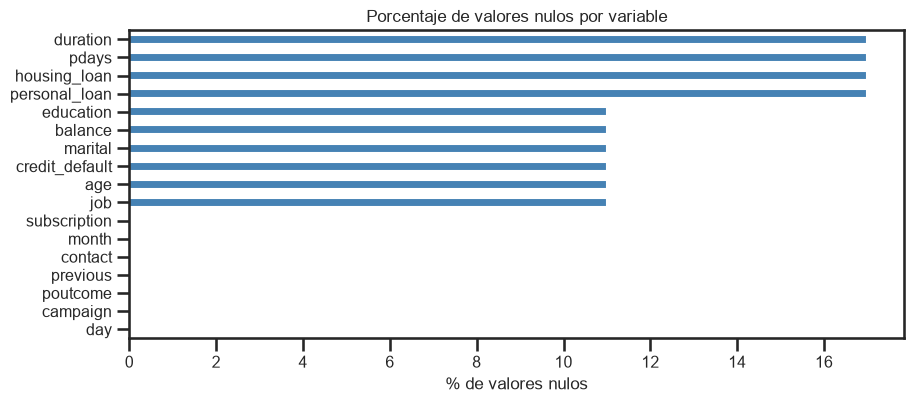

In [10]:
# gráfico de barras del porcentaje de nulos por variable
fig, ax = plt.subplots(figsize=(10, 4))
(percent * 100).sort_values().plot.barh(ax=ax, color='steelblue')
ax.set_xlabel('% de valores nulos')
ax.set_title('Porcentaje de valores nulos por variable')
guardar('eda_nulos')
plt.show()

En clase vimos que ante valores nulos hay que decidir si **eliminar los registros** (`dropna`) o **reemplazarlos** (por ejemplo por la mediana). Veamos cuántos clientes quedarían si elimináramos todas las filas con algún nulo:

In [11]:
# shape que quedaría si eliminamos todas las filas con al menos un NaN
sin_nulos = bank.dropna(how='any')
print(f'Con dropna nos quedaríamos con {sin_nulos.shape[0]} filas de {bank.shape[0]} '
      f'({sin_nulos.shape[0] / bank.shape[0]:.0%} del dataset)')

Con dropna nos quedaríamos con 10630 filas de 45211 (24% del dataset)


10 de las 17 columnas tienen nulos. de las filas totales, solo 10630 están completas, entonces si se eliminaran las filas con nulos se decartaría más de la mitad de los datos. En este caso se podría imputars los datos. Antes de decidirlo, revisamos si los clientes con datos faltantes se comportan distinto a los demás en cuanto a la suscripción:

In [12]:
# tasa de suscripción de los clientes con y sin nulo en cada variable
filas_tabla = []
for col in total[total > 0].index:                                   # recorremos las columnas con nulos
    es_nulo = bank[col].isnull()                                     # vector booleano: True si es nulo
    filas_tabla.append({'variable': col,
                        '% suscripción (con nulo)': bank.loc[es_nulo, 'subscription'].mean() * 100,
                        '% suscripción (sin nulo)': bank.loc[~es_nulo, 'subscription'].mean() * 100})
pd.DataFrame(filas_tabla).round(1)

,variable,% suscripción (con nulo),% suscripción (sin nulo)
0,personal_loan,11.6,11.7
1,pdays,12.2,11.6
2,housing_loan,11.7,11.7
3,duration,11.5,11.7
4,age,11.0,11.8
5,credit_default,11.8,11.7
6,education,12.8,11.6
7,job,11.2,11.8
8,marital,11.7,11.7
9,balance,12.1,11.6


Conclusiones sobre los nulos:
- Hay dos grupos de variables con nulos: ~11% en `age, job, marital, education, credit_default, balance` y ~17% en `housing_loan, personal_loan, duration, pdays`.
- La tasa de suscripción es prácticamente la misma con y sin nulos (diferencias de 1 punto porcentual o menos): los clientes con datos faltantes no son un grupo particular.
- **Decisión:** no eliminar filas, sino **imputar** (mediana para numéricas y moda para categóricas). La imputación se calcula solo con los datos de entrenamiento para evitar *data leakage* (ver notebook de preprocesamiento).

### Caso especial: `pdays` y `previous`

In [13]:
# pdays = -1 significa "sin contacto previo". Miramos qué valores toma pdays cuando previous == 0
print('Valores de pdays cuando previous == 0:')
print(bank.loc[bank['previous'] == 0, 'pdays'].value_counts(dropna=False))
print('\nNulos de pdays cuando previous > 0:', bank.loc[bank['previous'] > 0, 'pdays'].isnull().sum())

Valores de pdays cuando previous == 0:
pdays
-1.0    30685
 NaN     6269
Name: count, dtype: int64

Nulos de pdays cuando previous > 0: 1417


Cuando `previous == 0` (el cliente nunca fue contactado antes), `pdays` vale **siempre -1** o es nulo. Esto permite **completar de forma lógica** esos nulos con -1 sin inventar información. Los nulos de `pdays` de clientes que sí fueron contactados antes se imputarán por separado.

# Análisis

Ahora que terminamos con la limpieza general, analizamos:
1. La variable objetivo `subscription`
2. Las variables numéricas
3. Correlación lineal
4. Las variables categóricas

# 1) Variable objetivo: `subscription`

subscription
0    39922
1     5289
Name: count, dtype: int64
subscription
0    0.883
1    0.117
Name: proportion, dtype: float64


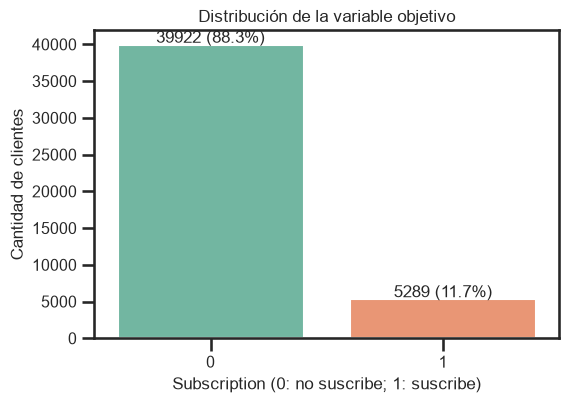

In [14]:
# cantidad y proporción de cada clase
print(bank['subscription'].value_counts())
print(bank['subscription'].value_counts(normalize=True).round(3))

conteo = bank['subscription'].value_counts().sort_index()
plt.figure(figsize=(6, 4))
ax = sns.countplot(x='subscription', data=bank, palette='Set2')
for i, v in enumerate(conteo):
    ax.text(i, v + 300, f'{v} ({v / len(bank):.1%})', ha='center')   # anotamos cantidad y porcentaje
plt.title('Distribución de la variable objetivo')
plt.xlabel('Subscription (0: no suscribe; 1: suscribe)')
plt.ylabel('Cantidad de clientes')
guardar('eda_target')
plt.show()

El dataset está **desbalanceado**: solo ~11,7% de los clientes se suscribe. Consecuencias para el modelado:
- Un modelo que siempre prediga "no suscribe" tendría **88% de accuracy** sin detectar a ningún suscriptor. Por eso, además del accuracy, usaremos la **sensibilidad**, la **especificidad** y el **AUC de la curva ROC** vistos en clase.
- La separación train/test debe mantener la proporción de clases (`stratify`).

# 2) Variables numéricas

## Estadística descriptiva

In [15]:
num_cols = ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']
bank[num_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,40238.0,40.93,10.63,18.0,33.0,39.0,48.00,95.0
balance,40238.0,1367.15,3079.45,-8019.0,72.0,448.0,1425.75,102127.0
day,45211.0,15.81,8.32,1.0,8.0,16.0,21.00,31.0
duration,37525.0,258.51,257.83,0.0,103.0,180.0,319.00,4918.0
campaign,45211.0,2.76,3.10,1.0,1.0,2.0,3.00,63.0
pdays,37525.0,40.02,99.73,-1.0,-1.0,-1.0,-1.00,871.0
previous,45211.0,0.58,2.30,0.0,0.0,0.0,0.00,275.0


## Histogramas

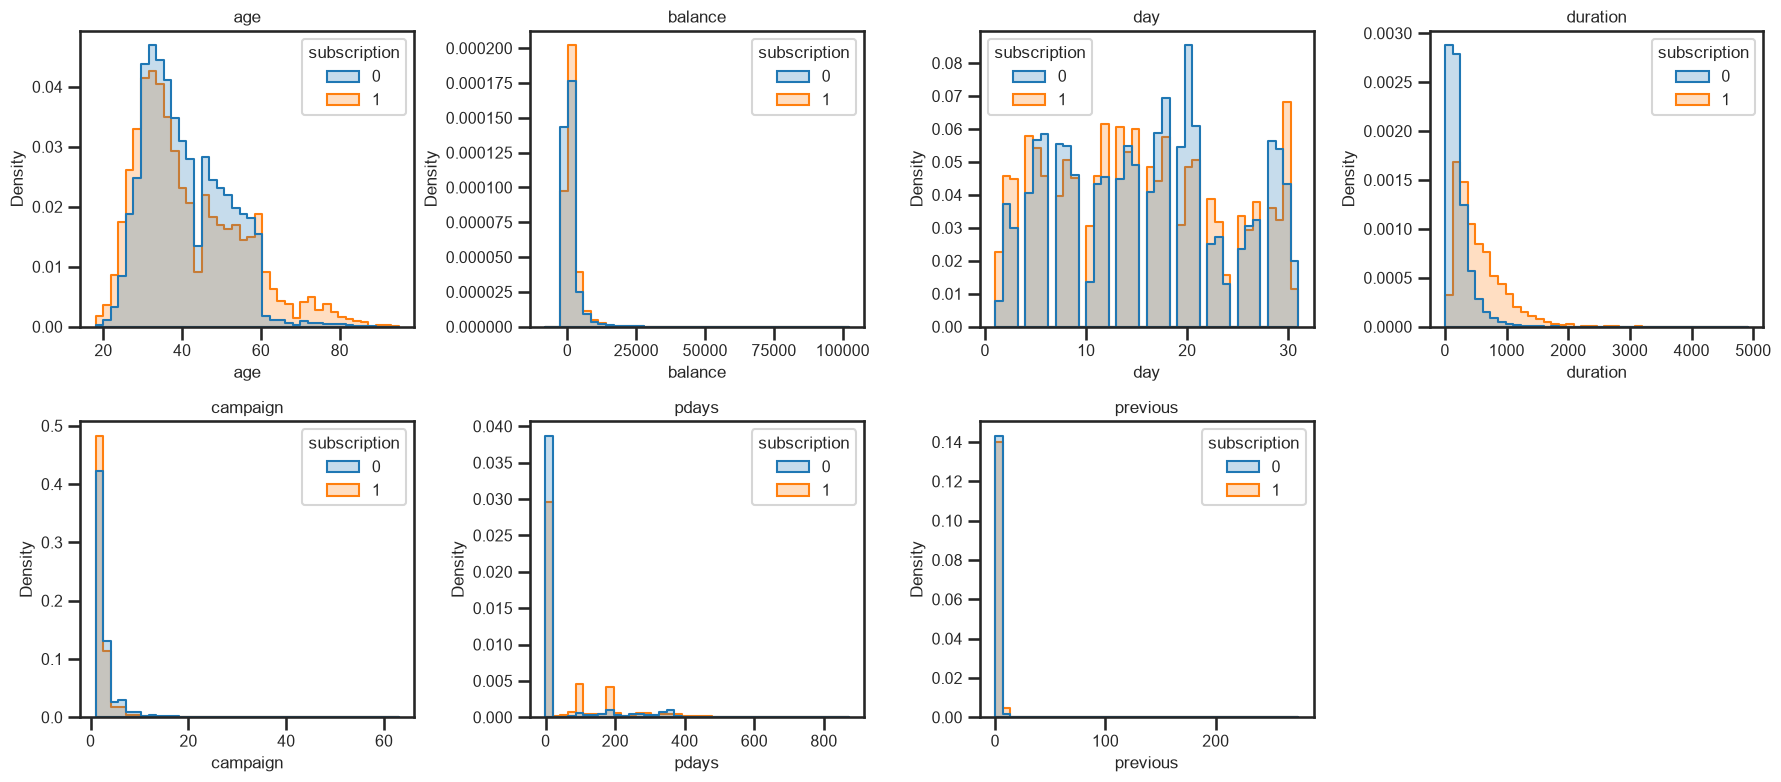

In [16]:
# histogramas de cada variable numérica separados por clase
fig, axs = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axs.ravel(), num_cols):
    sns.histplot(data=bank, x=col, hue='subscription', bins=40, stat='density',
                 common_norm=False, element='step', ax=ax)
    ax.set_title(col)
axs.ravel()[-1].axis('off')     # apagamos el último eje vacío
plt.tight_layout()
guardar('eda_histogramas')
plt.show()

Como vimos en clase, cuando los datos están muy concentrados conviene hacer un **cambio de escala** con $\log(1+x)$ para ver mejor la distribución (en `balance` recortamos los negativos a 0 para poder aplicar el logaritmo):

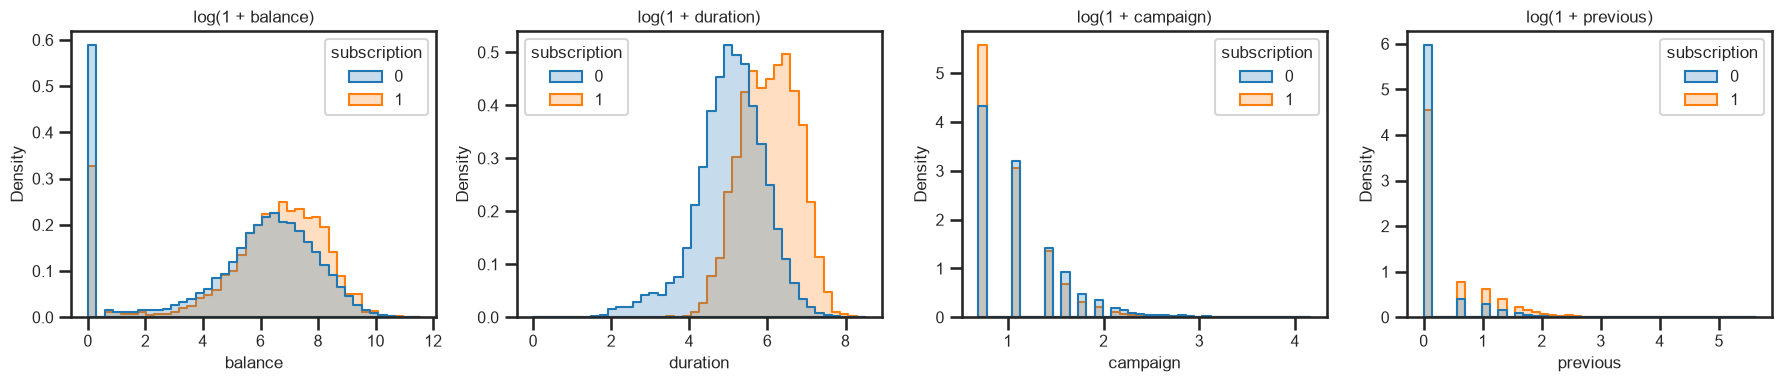

In [17]:
fig, axs = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axs, ['balance', 'duration', 'campaign', 'previous']):
    sns.histplot(x=np.log(1 + bank[col].clip(lower=0)), hue=bank['subscription'], bins=40,
                 stat='density', common_norm=False, element='step', ax=ax)
    ax.set_title(f'log(1 + {col})')
plt.tight_layout()
plt.show()

## Boxplots según la suscripción

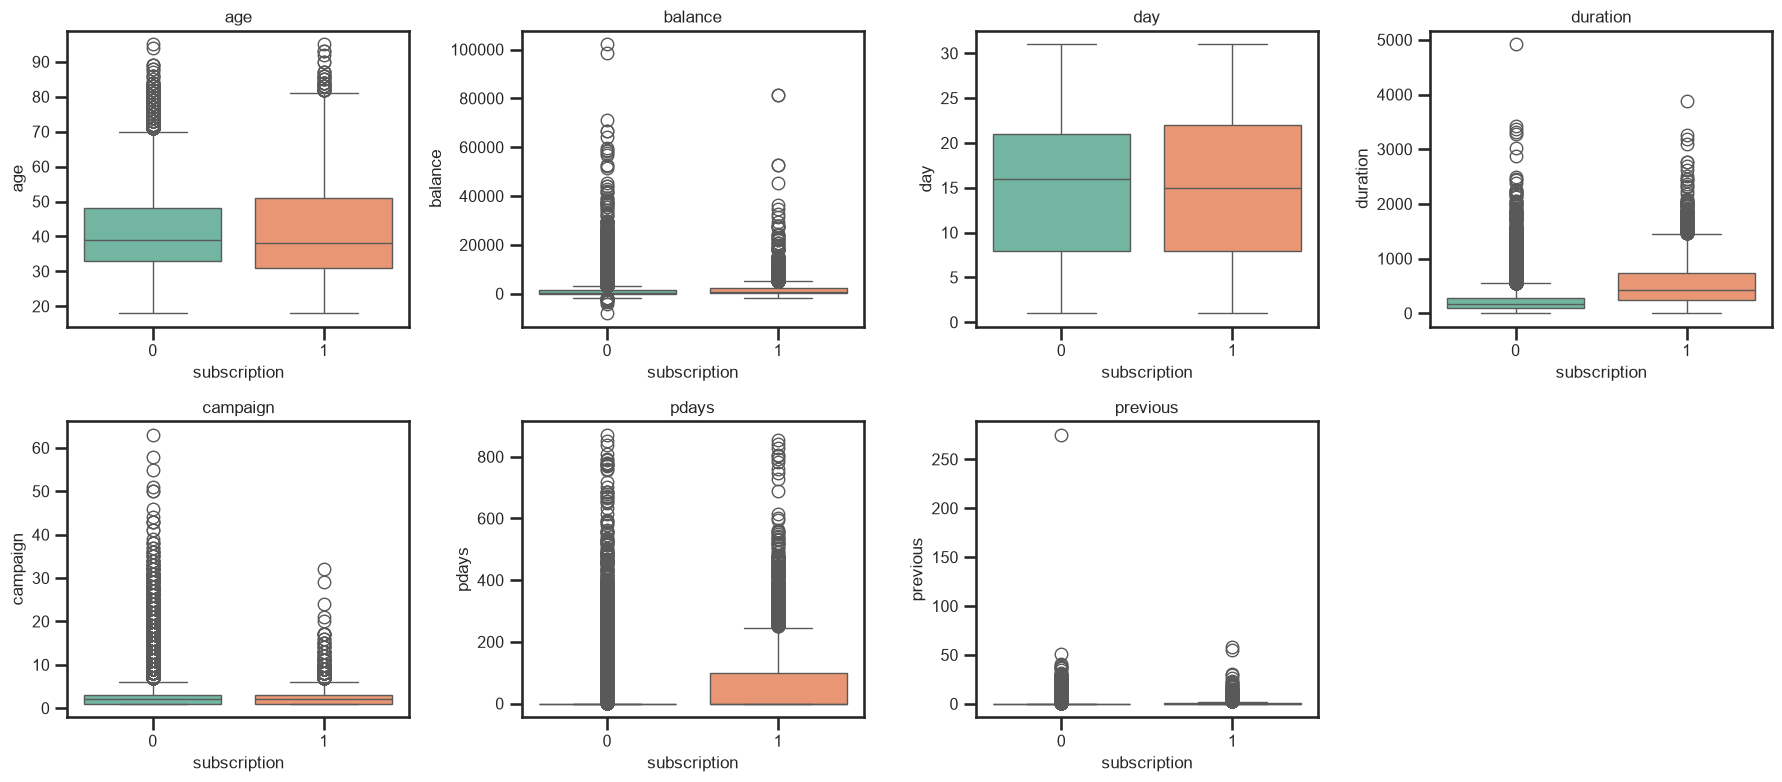

In [18]:
# boxplot de cada variable numérica para cada clase de subscription
fig, axs = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axs.ravel(), num_cols):
    sns.boxplot(data=bank, x='subscription', y=col, ax=ax, palette='Set2')
    ax.set_title(col)
axs.ravel()[-1].axis('off')
plt.tight_layout()
guardar('eda_boxplots')
plt.show()

In [19]:
# mediana de cada variable numérica para quienes suscriben y quienes no
bank.groupby('subscription')[num_cols].median().T

subscription,0,1
age,39.0,38.0
balance,417.0,728.0
day,16.0,15.0
duration,164.0,431.5
campaign,2.0,2.0
pdays,-1.0,-1.0
previous,0.0,0.0


In [20]:
# percentiles 1 y 99 de cada variable numérica, para ver qué tan extremos son los valores altos
bank[num_cols].quantile([0.01, 0.5, 0.99]).T

,0.01,0.50,0.99
age,23.00,39.0,71.00
balance,-625.63,448.0,13312.41
day,2.00,16.0,31.00
duration,11.00,180.0,1277.00
campaign,1.00,2.0,16.00
pdays,-1.00,-1.0,370.00
previous,0.00,0.0,8.90


Los valores extremos son **reales y plausibles** (saldos altos, llamadas largas, clientes muy contactados), no errores de carga. En `pdays`/`previous` más del 75% de los valores es -1/0, por lo que cualquier contacto previo queda fuera de los bigotes. **Decisión: no se eliminan**; se estandarizan las variables para los modelos sensibles a la escala.

## Relación de las numéricas con la suscripción

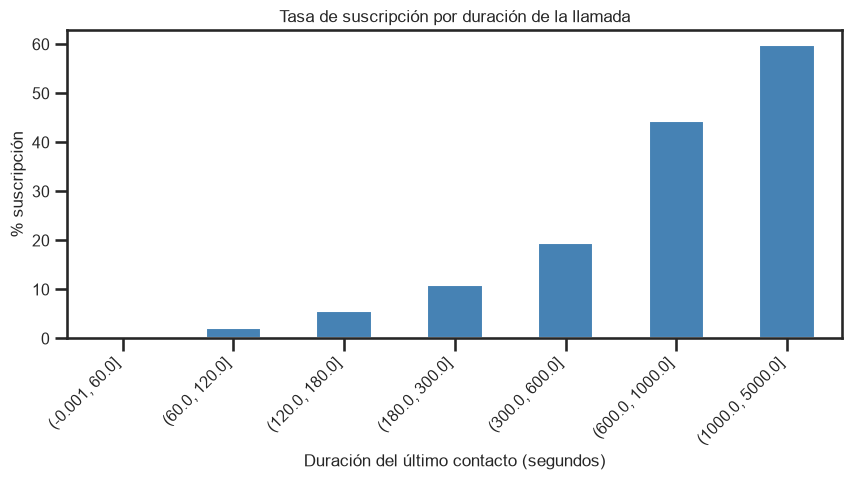

banda
(-0.001, 60.0]       0.2
(60.0, 120.0]        2.1
(120.0, 180.0]       5.6
(180.0, 300.0]      10.9
(300.0, 600.0]      19.5
(600.0, 1000.0]     44.3
(1000.0, 5000.0]    59.8
Name: subscription, dtype: float64

In [21]:
# bandas de duración de la llamada (en segundos) y tasa de suscripción en cada banda
bandas = [0, 60, 120, 180, 300, 600, 1000, 5000]
dur = bank[['duration', 'subscription']].dropna().copy()
dur['banda'] = pd.cut(dur['duration'], bins=bandas, include_lowest=True)
tasa = dur.groupby('banda')['subscription'].mean() * 100
plt.figure(figsize=(10, 4))
tasa.plot.bar(color='steelblue')
plt.ylabel('% suscripción')
plt.xlabel('Duración del último contacto (segundos)')
plt.title('Tasa de suscripción por duración de la llamada')
plt.xticks(rotation=45, ha='right')
guardar('eda_duration')
plt.show()
tasa.round(1)

`duration` es la variable más asociada a la suscripción: en las llamadas de más de 10 minutos la tasa está entre 44% y 60%, mientras que en las de menos de 1 minuto es prácticamente nula (0,2%).

**Atención:** la duración de la llamada **solo se conoce después de llamar** al cliente. Un modelo que la use sirve para explicar, pero **no para decidir a quién llamar antes de la campaña** (es una forma de *data leakage*). En el notebook de ML evaluaremos los modelos **con y sin** `duration`.

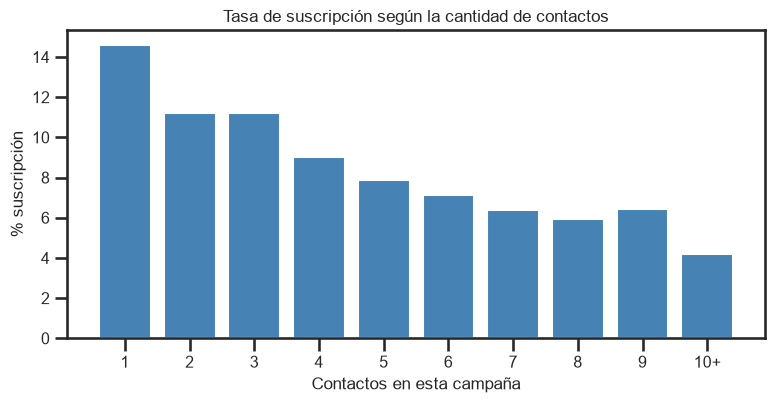

In [22]:
# tasa de suscripción según cantidad de contactos en la campaña (10 o más agrupados)
camp = bank.copy()
camp['campaign_grp'] = camp['campaign'].clip(upper=10)
tasa = camp.groupby('campaign_grp')['subscription'].mean() * 100
plt.figure(figsize=(9, 4))
plt.bar([str(i) for i in range(1, 10)] + ['10+'], tasa.values, color='steelblue')
plt.xlabel('Contactos en esta campaña'); plt.ylabel('% suscripción')
plt.title('Tasa de suscripción según la cantidad de contactos')
guardar('eda_campaign')
plt.show()

Cuanto más se insiste con un cliente en la misma campaña, **menor** es la probabilidad de que suscriba: con 1 contacto la tasa es 14,6% y a partir de 4 llamadas cae por debajo del 10% (4,2% con 10 o más).

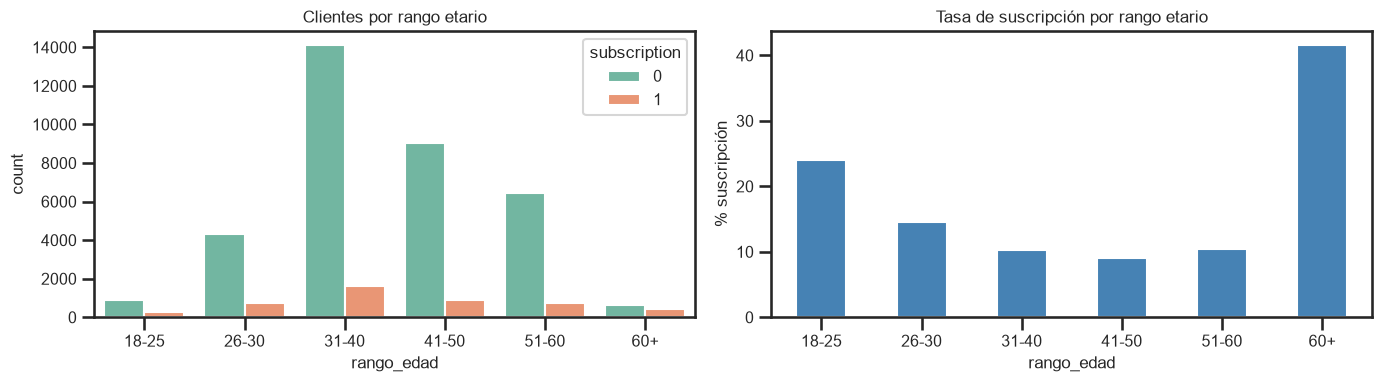

In [23]:
# rango etario (binning) y tasa de suscripción
edad = bank[['age', 'subscription']].dropna().copy()
edad['rango_edad'] = pd.cut(edad['age'], bins=[17, 25, 30, 40, 50, 60, 100],
                            labels=['18-25', '26-30', '31-40', '41-50', '51-60', '60+'])
fig, axs = plt.subplots(1, 2, figsize=(14, 4))
sns.countplot(data=edad, x='rango_edad', hue='subscription', palette='Set2', ax=axs[0])
axs[0].set_title('Clientes por rango etario')
(edad.groupby('rango_edad')['subscription'].mean() * 100).plot.bar(ax=axs[1], color='steelblue', rot=0)
axs[1].set_ylabel('% suscripción'); axs[1].set_title('Tasa de suscripción por rango etario')
plt.tight_layout()
guardar('eda_edad')
plt.show()

La relación edad–suscripción **no es lineal (forma de U)**: los menores de 25 y los mayores de 60 suscriben mucho más que los clientes de mediana edad, que son la mayoría de la cartera. Esto sugiere que modelos no lineales (árboles) pueden aprovechar mejor esta variable.

# 3) Correlación lineal (Pearson)

$$r = \frac{\sum_{i}^{n}(x_i - \bar{x})(y_i - \bar{y})}{\left[\sum_{i}^{n}(x_i - \bar{x})^2 \sum_{i}^{n}(y_i - \bar{y})^2\right]^{1/2}}$$
La correlación de Pearson varía entre -1 y 1 e indica si dos variables se comportan linealmente una respecto de la otra. Incluimos `subscription` (0/1) para ver qué variables numéricas se asocian linealmente con la suscripción. **Importante: correlación no implica causalidad.**

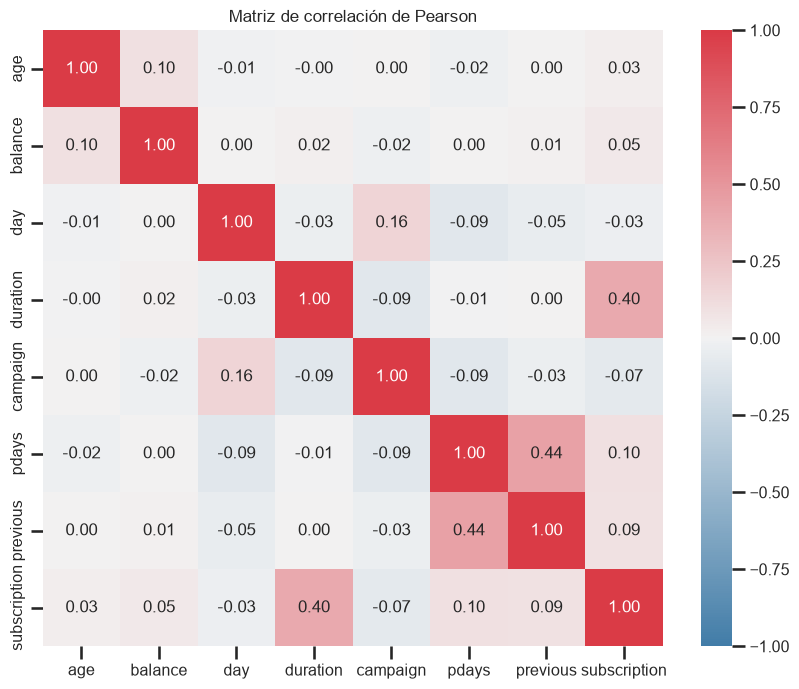

In [24]:
corrmat = bank[num_cols + ['subscription']].corr()
f, ax = plt.subplots(figsize=(10, 8))
ax = sns.heatmap(corrmat, annot=True, fmt='.2f', cmap=sns.diverging_palette(240, 10, as_cmap=True), vmin=-1, vmax=1)
plt.title('Matriz de correlación de Pearson')
guardar('eda_correlaciones')
plt.show()

In [25]:
# correlación de cada variable numérica con subscription, ordenada por valor absoluto
corrmat['subscription'].drop('subscription').sort_values(key=abs, ascending=False).round(3)

duration    0.398
pdays       0.100
previous    0.093
campaign   -0.073
balance     0.052
day        -0.028
age         0.026
Name: subscription, dtype: float64

- `duration` es la variable numérica con mayor correlación con la suscripción (≈ 0,40).
- `pdays` y `previous` están correlacionadas entre sí (≈ 0,45) y con la suscripción: miden lo mismo, si el cliente fue contactado en una campaña anterior.
- El resto de las correlaciones son bajas. Una correlación lineal baja no implica que la variable no sirva: por ejemplo, la edad tiene una relación en forma de U que Pearson no capta.

# 4) Variables categóricas

In [26]:
cat_cols = ['job', 'marital', 'education', 'credit_default', 'housing_loan',
            'personal_loan', 'contact', 'month', 'poutcome']
# cantidad de categorías y categoría más frecuente de cada variable
bank[cat_cols].describe().T

,count,unique,top,freq
job,40238,12,blue-collar,8707
marital,40238,3,married,24222
education,40238,4,secondary,20645
credit_default,40238,2,no,39511
housing_loan,37525,2,yes,20817
personal_loan,37525,2,no,31536
contact,45211,3,cellular,29285
month,45211,12,may,13766
poutcome,45211,4,unknown,36959


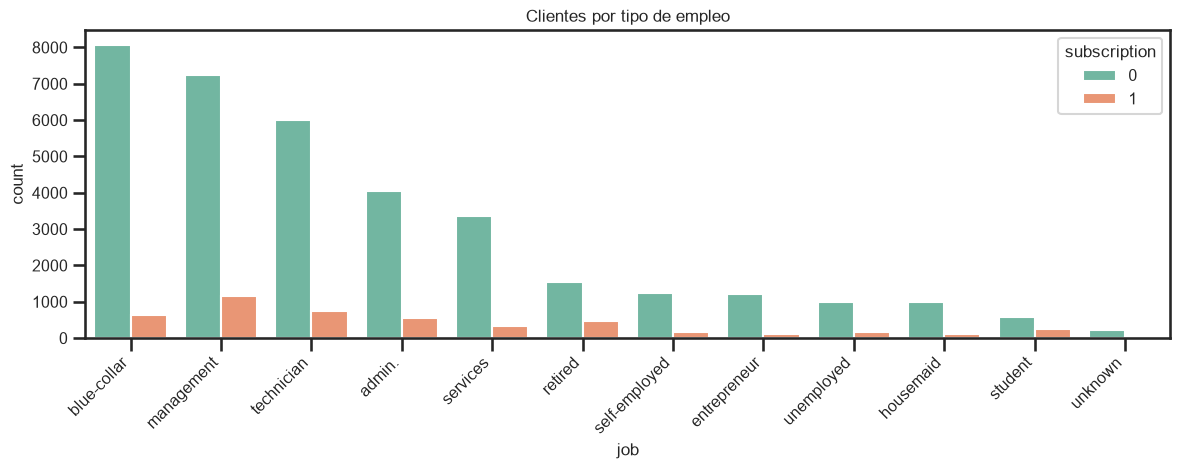

In [27]:
# cantidad de clientes por tipo de empleo
plt.figure(figsize=(14, 4))
g = sns.countplot(data=bank, x='job', hue='subscription', palette='Set2',
                  order=bank['job'].value_counts().index)
g.set_xticklabels(g.get_xticklabels(), rotation=45, ha='right')
plt.title('Clientes por tipo de empleo')
plt.show()

## Tasa de suscripción por categoría
Para cada categoría calculamos el promedio de `subscription` con `groupby`, que es la proporción de clientes que se suscribió. La línea roja marca el promedio general.

In [28]:
# tabla pivote: tasa de suscripción (%) según el resultado de la campaña anterior y el medio de contacto
pd.pivot_table(bank, values='subscription', index='poutcome', columns='contact',
               aggfunc='mean', fill_value=0).round(3) * 100

contact,cellular,telephone,unknown
poutcome,,,
failure,12.7,12.0,12.9
other,17.1,12.5,18.5
success,65.0,65.8,25.0
unknown,12.0,11.1,4.0


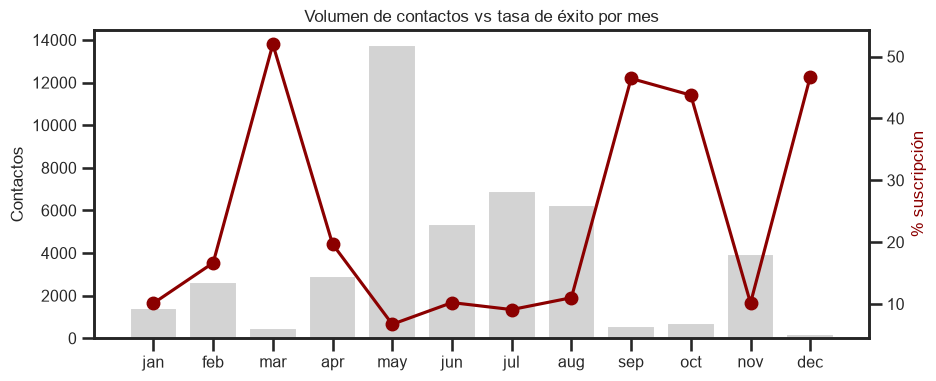

In [29]:
# cantidad de contactos por mes vs tasa de éxito por mes
orden_meses = ['jan', 'feb', 'mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec']
t = bank.groupby('month')['subscription'].agg(['mean', 'count']).loc[orden_meses]
fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.bar(t.index, t['count'], color='lightgray')
ax1.set_ylabel('Contactos')
ax2 = ax1.twinx()                                # segundo eje y para la tasa
ax2.plot(t.index, t['mean'] * 100, color='darkred', marker='o')
ax2.set_ylabel('% suscripción', color='darkred')
ax1.set_title('Volumen de contactos vs tasa de éxito por mes')
guardar('eda_meses')
plt.show()

Observaciones sobre las categóricas:
- **`poutcome`** es la categórica más informativa: si la campaña anterior fue un **éxito**, ~65% vuelve a suscribir (vs 11,7% promedio).
- **`month`**: mayo concentra ~30% de los contactos pero tiene la peor tasa (~7%); marzo, septiembre, octubre y diciembre tienen pocos contactos pero tasas cercanas al 50%. Las campañas masivas parecen tener menor efectividad.
- **`contact`**: los clientes con medio de contacto `unknown` suscriben mucho menos (4%).
- **`job`**: estudiantes y jubilados son los perfiles con mayor tasa; *blue-collar* la menor.
- Tener **préstamo hipotecario o personal** reduce la probabilidad de suscribir; `credit_default` casi no tiene clientes en mora (1,8%).
- Varias variables tienen la categoría `unknown` además de los nulos: la mantenemos como una categoría más porque es información del banco.

# Conclusiones del EDA
1. **Dataset**: 45.211 clientes, 16 variables explicativas (7 numéricas, 9 categóricas) y sin filas duplicadas.
2. **Nulos**: entre 11% y 17% en 10 variables, dispersos al azar y sin relación con la suscripción. Eliminar filas haría perder más del 75% de los datos, por lo que se **imputan** (mediana para numéricas, moda para categóricas) usando solo el set de train. Los nulos de `pdays` con `previous = 0` se completan con -1.
3. **Desbalance**: 11,7% de suscriptos → evaluar con sensibilidad, especificidad y AUC-ROC además del accuracy, y separar train/test estratificado.
4. **Variables más relacionadas con la suscripción**: `duration` (con la salvedad de que solo se conoce después de la llamada), `poutcome`, `month`, `contact`, `pdays/previous`, `housing_loan` y `age` (relación no lineal).
5. **Outliers**: se conservan (son valores reales); se estandarizan las numéricas para los modelos sensibles a la escala (KNN, regresión logística, redes neuronales, PCA).
6. Las categóricas requieren **variables dummies (one-hot encoding)**, lo que lleva el espacio de features a ~50 dimensiones: motivación para aplicar **PCA** como reducción de dimensionalidad.